In [1]:
#  Remove the _001 from a folder of tif images
import os

folder_path = '/Users/allisonpickle/Desktop/Test'

for filename in os.listdir(folder_path):
        if filename.endswith('_001.tif'):
            new_filename = filename.replace('_001.tif', '.tif')
            os.rename(os.path.join(folder_path, filename), os.path.join(folder_path, new_filename))

In [ ]:
import os
from scipy.ndimage import gaussian_filter
import tifffile as tiff

def process_images(input_folder, output_folder, sigma):
    """
    Apply Gaussian filter to all .tif images in the input folder and save the results to the output folder.

    Parameters
    ----------
    input_folder : str
        Path to the folder containing the input images.
    output_folder : str
        Path to the folder where the processed images will be saved.
    sigma : float
        Standard deviation for Gaussian kernel.

    Returns
    -------
    None
    """
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    for filename in os.listdir(input_folder):
        if filename.endswith('.tif'):
            file_path = os.path.join(input_folder, filename)
            image = tiff.imread(file_path)
            filtered_image = gaussian_filter(image, sigma=sigma)
            
            output_file_path = os.path.join(output_folder, filename)
            tiff.imwrite(output_file_path, filtered_image)

# Example usage
input_folder = '/Users/allisonpickle/Desktop/Test'
output_folder = '/Users/allisonpickle/Desktop/Test/Processed'
sigma = 2.0
process_images(input_folder, output_folder, sigma)

Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_4_2_Confocal CY5.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_1_3_Confocal DAPI.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_1_2_Confocal DAPI.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_2_2_Confocal GFP.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_1_1_Confocal DAPI.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_4_3_Confocal CY5.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_1_4_Confocal DAPI.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_2_3_Confocal GFP.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_3_3_Confocal TRITC.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_3_2_Confocal TRITC.tif
Processed and saved: /Users/allisonpickle/Desktop/Test/Processed/D3_01_2

In [7]:
import cv2
import numpy as np

def apply_otsu_threshold(input_folder, output_folder):
    """
    Apply Otsu threshold to all .tif images with 'Confocal TRITC' or 'Confocal DAPI' in the filename in the input folder 
    and save the results to the output folder.

    Parameters
    ----------
    input_folder : str
        Path to the folder containing the input images.
    output_folder : str
        Path to the folder where the thresholded images will be saved.

    Returns
    -------
    None
    """
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    for filename in os.listdir(input_folder):
        if filename.endswith('.tif') and ('Confocal TRITC' in filename or 'Confocal DAPI' in filename):
            file_path = os.path.join(input_folder, filename)
            image = tiff.imread(file_path)
            
            # Apply Otsu threshold
            _, thresholded_image = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            
            output_file_path = os.path.join(output_folder, filename)
            tiff.imwrite(output_file_path, thresholded_image)

# Example usage
apply_otsu_threshold(input_folder, thresholded_folder)


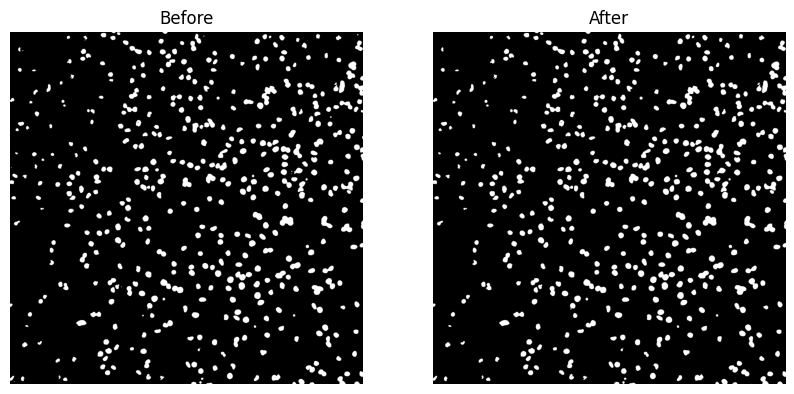

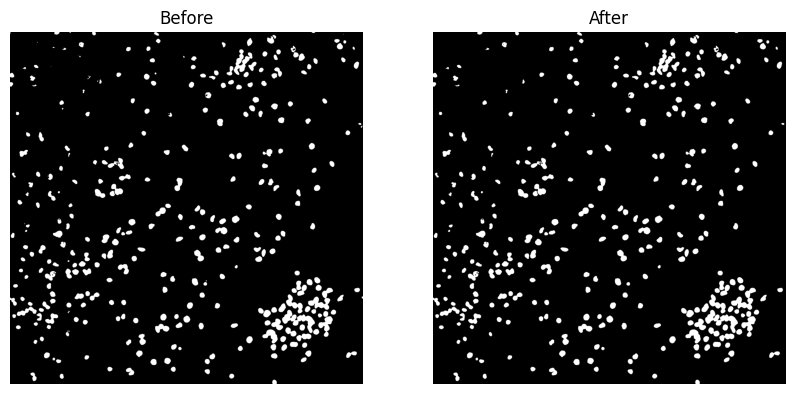

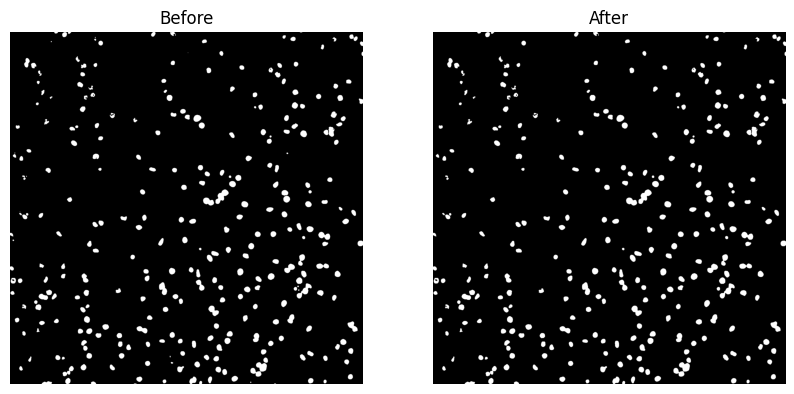

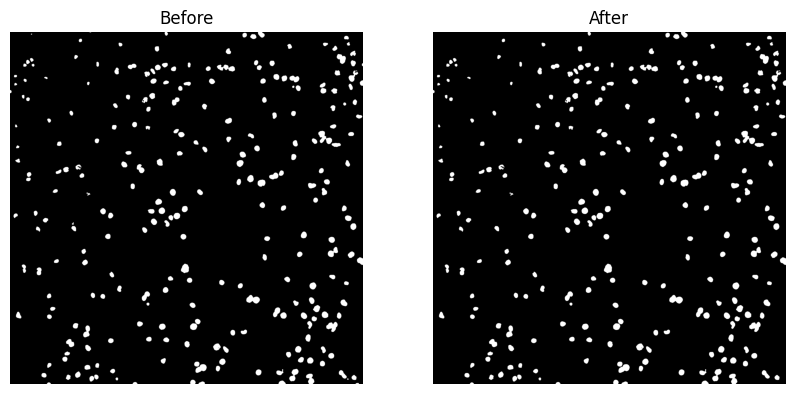

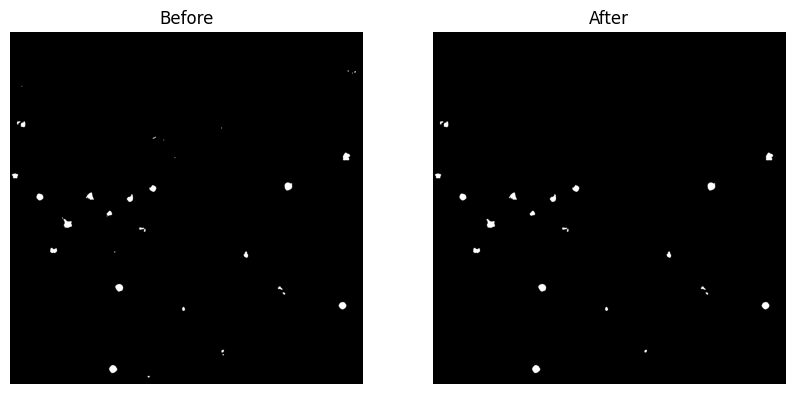

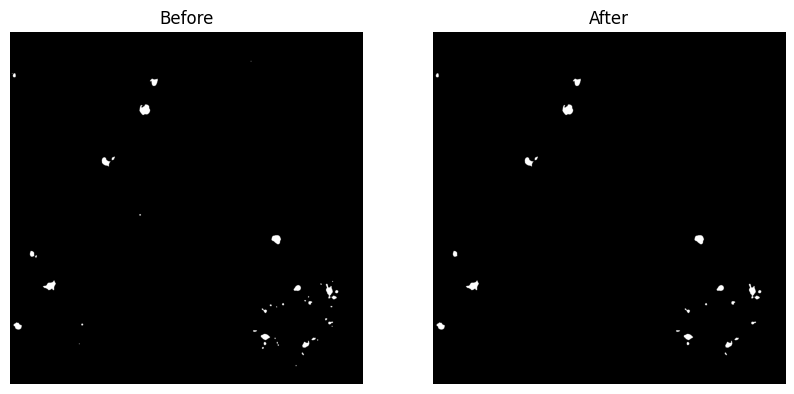

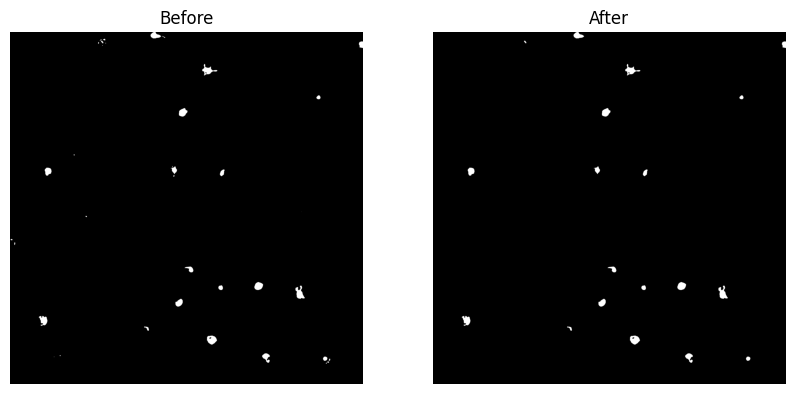

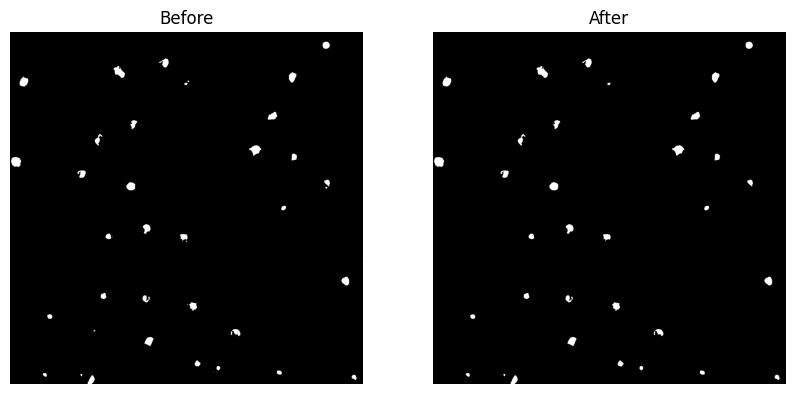

In [11]:
from skimage import morphology

import matplotlib.pyplot as plt

def remove_islands(input_folder, output_folder, min_size):
    """
    Remove islands of a specified size in images whose fifth element is 'Confocal DAPI' or 'Confocal TRITC'.
    Display before and after images side by side.

    Parameters
    ----------
    input_folder : str
        Path to the folder containing the input images.
    output_folder : str
        Path to the folder where the processed images will be saved.
    min_size : int
        Minimum size of islands to keep.

    Returns
    -------
    None
    """
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    for filename in os.listdir(input_folder):
        if filename.endswith('.tif') and ('Confocal DAPI' in filename or 'Confocal TRITC' in filename):
            file_path = os.path.join(input_folder, filename)
            image = tiff.imread(file_path)
            
            # Remove small objects (islands)
            processed_image = morphology.remove_small_objects(image > 0, min_size=min_size)
            
            output_file_path = os.path.join(output_folder, filename)
            tiff.imwrite(output_file_path, processed_image.astype(np.uint8) * 255)
            
            # Display before and after images side by side
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(image, cmap='gray')
            axes[0].set_title('Before')
            axes[0].axis('off')
            
            axes[1].imshow(processed_image, cmap='gray')
            axes[1].set_title('After')
            axes[1].axis('off')
            
            plt.show()

# Example usage
min_size = 100

output_folder = '/Users/allisonpickle/Desktop/Test/Thresholded'
input_folder = '/Users/allisonpickle/Desktop/Test/Thresholded'
remove_islands(input_folder, output_folder, min_size)

In [ ]:
import os
import matplotlib.pyplot as plt
from skimage.morphology import disk, white_tophat
import tifffile as tiff

def apply_white_tophat(input_folder, disk_size):
    """
    Apply white tophat filter to all .tif images in the input folder and save the results to the same folder.
    Display before and after images side by side.

    Parameters
    ----------
    input_folder : str
        Path to the folder containing the input images.
    disk_size : int
        Size of the disk-shaped structuring element.

    Returns
    -------
    None
    """
    for filename in os.listdir(input_folder):
        if filename.endswith('.tif'):
            file_path = os.path.join(input_folder, filename)
            image = tiff.imread(file_path)
            
            # Apply white tophat filter
            selem = disk(disk_size)
            processed_image = white_tophat(image, selem)
            
            # Save the processed image in the same folder
            tiff.imwrite(file_path, processed_image)
            
            # Display before and after images side by side
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(image, cmap='gray')
            axes[0].set_title('Before')
            axes[0].axis('off')
            
            axes[1].imshow(processed_image, cmap='gray')
            axes[1].set_title('After')
            axes[1].axis('off')
            
            plt.show()

# Example usage
disk_size= 100
input_folder = '/Users/allisonpickle/Desktop/Test'
apply_white_tophat(input_folder, disk_size)


In [1]:
def Remove_DAPI_Islands(folder_path, radius):
    from skimage.morphology import disk
    from skimage import morphology
    import os
    from skimage import io
    import matplotlib.pyplot as plt
    """Process all TIFF images in a folder by applying white tophat transformation and saving the final images.

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the TIFF images
    output_folder : str
        Path to the folder to save the final images
    magnification : str
        Magnification level of the images

    Returns
    -------
    None
    """
    # Get a list of all TIFF image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tif')]

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Read the image file into a NumPy array
        image = io.imread(image_path)

        footprint = disk(radius)
        res = morphology.white_tophat(image, footprint)

        # final_image_path = os.path.join(folder_path, image_file)
        # io.imsave(final_image_path, image - res)
        # dislpay the image 

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(image, cmap='gray')
        axes[0].set_title('Before')
        axes[0].axis('off')

        axes[1].imshow(res, cmap='gray')
        axes[1].set_title('After')
        axes[1].axis('off')

        plt.show()

radius = 10000
folder_path = '/Users/allisonpickle/Desktop/Test'
Remove_DAPI_Islands(folder_path, radius)


MemoryError: 

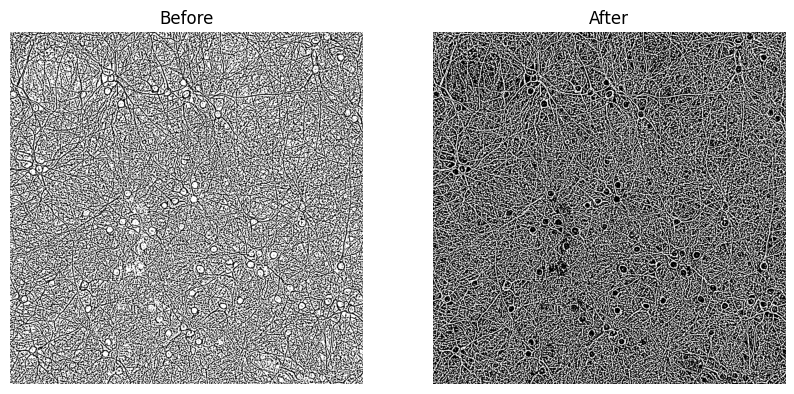

In [6]:
import cv2
import os
import tifffile as tiff

import matplotlib.pyplot as plt

def reverse_threshold(input_folder):
    """
    Apply reverse threshold to all .tif images in the input folder and save the results to the same folder.
    Display before and after images side by side.

    Parameters
    ----------
    input_folder : str
        Path to the folder containing the input images.

    Returns
    -------
    None
    """
    for filename in os.listdir(input_folder):
        if filename.endswith('.tif'):
            file_path = os.path.join(input_folder, filename)
            image = tiff.imread(file_path)
            
            # Apply reverse threshold
            _, thresholded_image = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            reversed_image = cv2.bitwise_not(thresholded_image)
            
            # Save the processed image in the same folder
            tiff.imwrite(file_path, reversed_image)
            
            # Display before and after images side by side
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(image, cmap='gray')
            axes[0].set_title('Before')
            axes[0].axis('off')
            
            axes[1].imshow(reversed_image, cmap='gray')
            axes[1].set_title('After')
            axes[1].axis('off')
            
            plt.show()

# Example usage
reverse_threshold(folder_path)

In [ ]:
run("Gaussian Blur...", "sigma=1");
run("Subtract Background...", "rolling=50");
run("Bandpass Filter...", "filter_large=40 filter_small=3 suppress=None tolerance=5 autoscale saturate");
run("Convolve...", "text1=[-1 -1 -1 -1 -1\n-1 -1 -1 -1 -1\n-1 -1 24 -1 -1\n-1 -1 -1 -1 -1\n-1 -1 -1 -1 -1\n] normalize");


In [3]:
import os
import tifffile as tiff
import matplotlib.pyplot as plt
from skimage.morphology import disk, white_tophat, binary_fill_holes
import numpy as np

def fill_holes_in_images(folder_path):
    """
    Fill holes in all .tif images in the folder and display the results before and after.

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the input images.

    Returns
    -------
    None
    """
    for filename in os.listdir(folder_path):
        if filename.endswith('.tif'):
            file_path = os.path.join(folder_path, filename)
            image = tiff.imread(file_path)
            
            # Fill holes in the image
            filled_image = binary_fill_holes(image > 0)
            
            # Save the processed image in the same folder
            processed_image_path = os.path.join(folder_path, 'Processed', filename)
            tiff.imwrite(processed_image_path, filled_image.astype(np.uint8) * 255)
            print(f"Processed and saved: {processed_image_path}")
            
            # Display before and after images side by side
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(image, cmap='gray')
            axes[0].set_title('Before')
            axes[0].axis('off')
            
            axes[1].imshow(filled_image, cmap='gray')
            axes[1].set_title('After')
            axes[1].axis('off')
            
            plt.show()

# Example usage
folder_path = '/Users/allisonpickle/Desktop/Test/Neurons'
fill_holes_in_images(folder_path)

ImportError: cannot import name 'binary_fill_holes' from 'skimage.morphology' (/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/skimage/morphology/__init__.py)